In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv("/content/amazon.csv")
print(data)

      product_id                                       product_name  \
0     B07JW9H4J1  Wayona Nylon Braided USB to Lightning Fast Cha...   
1     B098NS6PVG  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...   
2     B096MSW6CT  Sounce Fast Phone Charging Cable & Data Sync U...   
3     B08HDJ86NZ  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...   
4     B08CF3B7N1  Portronics Konnect L 1.2M Fast Charging 3A 8 P...   
...          ...                                                ...   
1460  B08L7J3T31  Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...   
1461  B01M6453MB  Prestige Delight PRWO Electric Rice Cooker (1 ...   
1462  B009P2LIL4  Bajaj Majesty RX10 2000 Watts Heat Convector R...   
1463  B00J5DYCCA  Havells Ventil Air DSP 230mm Exhaust Fan (Pist...   
1464  B01486F4G6  Borosil Jumbo 1000-Watt Grill Sandwich Maker (...   

                                               category discounted_price  \
0     Computers&Accessories|Accessories&Peripherals|...             ₹39

In [ ]:
data.isnull()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1461,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1462,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1463,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.dropna(subset=['rating_count'], inplace=True)

In [ ]:
data[data['rating_count'].isnull()]

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link


In [ ]:
data['rating_count'].isnull().sum()

np.int64(0)

In [ ]:
data['discounted_price']=data['discounted_price'].astype(str).str.replace('₹','').str.replace(',','').astype(float)
data['actual_price']=data['actual_price'].astype(str).str.replace('₹','').str.replace(',','').astype(float)
data['discount_percentage']=data['discount_percentage'].astype(str).str.replace('%','').astype(float)

In [ ]:
data[data['rating'].isnull()]

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link


In [ ]:
data[pd.to_numeric(data['rating'], errors='coerce').isnull()]

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1279,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...",2099.0,2499.0,16.0,|,992,No Installation is provided for this product|1...,"AGTDSNT2FKVYEPDPXAA673AIS44A,AER2XFSWNN4LAUCJ5...","Divya,Dr Nefario,Deekshith,Preeti,Prasanth R,P...","R2KKTKM4M9RDVJ,R1O692MZOBTE79,R2WRSEWL56SOS4,R...","Decent product,doesn't pick up sand,Ok ok,Must...","Does the job well,doesn't work on sand. though...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Vacuum-Cle...


In [ ]:
data['rating'] = pd.to_numeric(data['rating'], errors='coerce')
data.dropna(subset=['rating'], inplace=True)

In [ ]:
data['rating_count'].head()

,rating_count
0,"24,269"
1,"43,994"
2,"7,928"
3,"94,363"
4,"16,905"


In [ ]:
data['discount_percentage']=data['discount_percentage'].astype(str).str.replace('%','').astype(float)
data['actual_price']=data['actual_price'].astype(str).str.replace('₹','').str.replace(',','').astype(float)
data['final_price']=data['actual_price'] * (1-data['discount_percentage']/100)

In [ ]:
data['final_price']

,final_price
0,395.64
1,198.93
2,189.90
3,328.53
4,155.61
...,...
1460,376.79
1461,2283.75
1462,2217.60
1463,1398.60


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1462 entries, 0 to 1464
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1462 non-null   object 
 1   product_name         1462 non-null   object 
 2   category             1462 non-null   object 
 3   discounted_price     1462 non-null   float64
 4   actual_price         1462 non-null   float64
 5   discount_percentage  1462 non-null   float64
 6   rating               1462 non-null   float64
 7   rating_count         1462 non-null   object 
 8   about_product        1462 non-null   object 
 9   user_id              1462 non-null   object 
 10  user_name            1462 non-null   object 
 11  review_id            1462 non-null   object 
 12  review_title         1462 non-null   object 
 13  review_content       1462 non-null   object 
 14  img_link             1462 non-null   object 
 15  product_link         1462 non-null   object

In [ ]:
print('Shape', data.shape)

Shape (1462, 17)


In [ ]:
print(data.columns.tolist())

['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link', 'final_price']


In [ ]:
print(data.dtypes)

product_id              object
product_name            object
category                object
discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count            object
about_product           object
user_id                 object
user_name               object
review_id               object
review_title            object
review_content          object
img_link                object
product_link            object
final_price            float64
dtype: object


In [ ]:
print(data.describe())

       discounted_price   actual_price  discount_percentage       rating  \
count       1462.000000    1462.000000          1462.000000  1462.000000   
mean        3129.981826    5453.087743            47.672367     4.096717   
std         6950.548042   10884.467444            21.613905     0.289497   
min           39.000000      39.000000             0.000000     2.000000   
25%          325.000000     800.000000            32.000000     4.000000   
50%          799.000000    1670.000000            50.000000     4.100000   
75%         1999.000000    4321.250000            63.000000     4.300000   
max        77990.000000  139900.000000            94.000000     5.000000   

        final_price  
count   1462.000000  
mean    3130.543776  
std     6959.627470  
min       38.870000  
25%      325.357500  
50%      799.600000  
75%     2008.497500  
max    78344.000000  


In [ ]:
for col in ['category','rating']:
  print(f"\n{col}")
  print(data[col].nunique())


category
211

rating
25


In [ ]:
print('unique_product:',data['product_name'].nunique())

unique_product: 1334


In [ ]:
category_count=data['category'].value_counts()
print(category_count.head(10))

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        231
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Home&Kitch

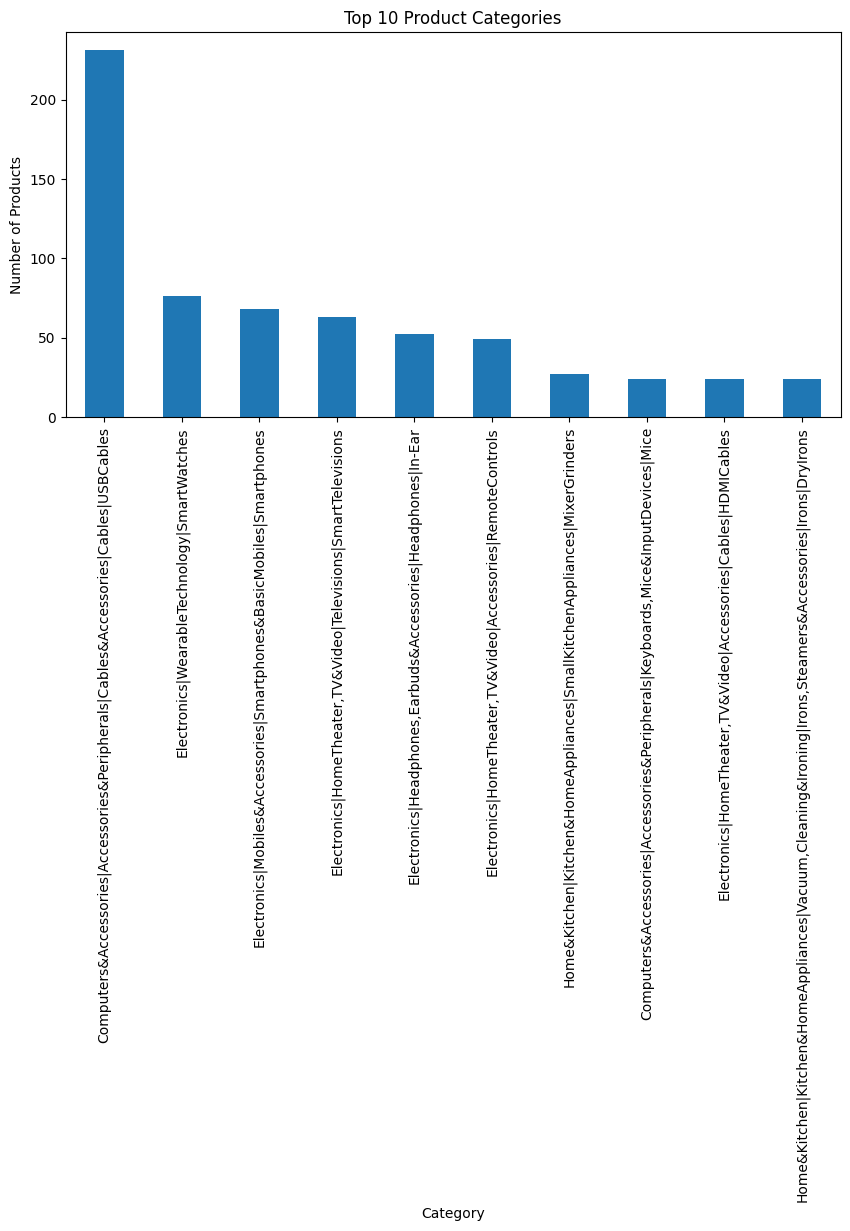

In [ ]:
category_count.head(10).plot(kind='bar',figsize=(10,5))
plt.title('Top 10 Product Categories')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=90)
plt.show()

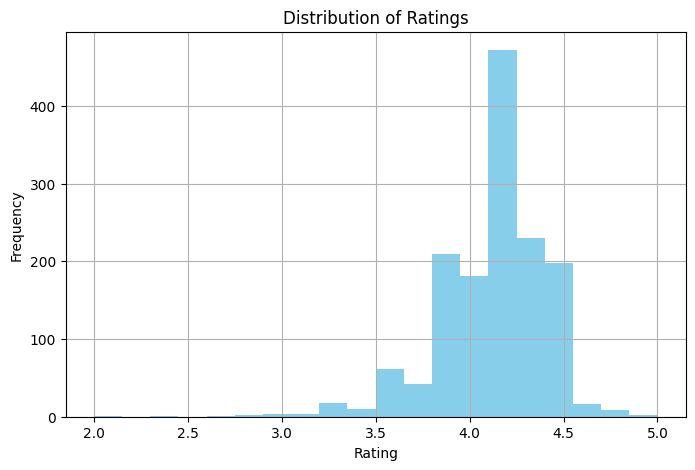

In [ ]:
plt.figure(figsize=(8, 5))
data['rating'].hist(bins=20, color='skyblue')
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

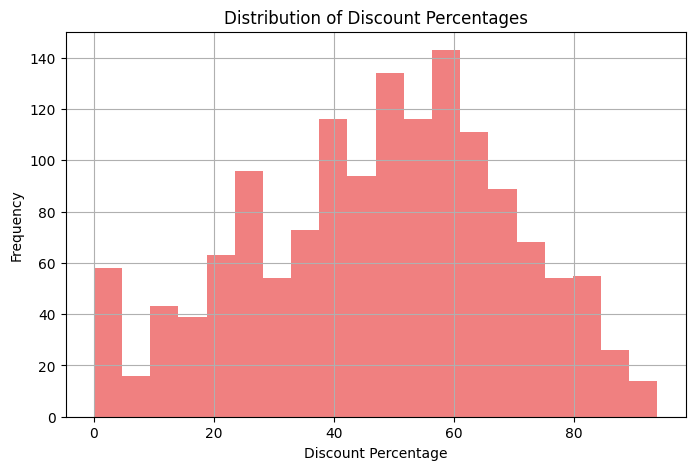

In [ ]:
plt.figure(figsize=(8, 5))
data['discount_percentage'].hist(bins=20, color='lightcoral')
plt.title('Distribution of Discount Percentages')
plt.xlabel('Discount Percentage')
plt.ylabel('Frequency')
plt.show()

In [ ]:
top_products=data.sort_values(
   by='rating',ascending=False
   )[['product_name','rating']].head(10)
print(top_products)


                                           product_name  rating
775   Amazon Basics Wireless Mouse | 2.4 GHz Connect...     5.0
174   Syncwire LTG to USB Cable for Fast Charging Co...     5.0
1145  Swiffer Instant Electric Water Heater Faucet T...     4.8
1201  Oratech Coffee Frother electric, milk frother ...     4.8
1299  Instant Pot Air Fryer, Vortex 2QT, Touch Contr...     4.8
1226  Zuvexa USB Rechargeable Electric Foam Maker - ...     4.7
1275  Multifunctional 2 in 1 Electric Egg Boiling St...     4.7
459   Spigen EZ Fit Tempered Glass Screen Protector ...     4.7
1223  FIGMENT Handheld Milk Frother Rechargeable, 3-...     4.7
249   Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...     4.7


In [ ]:
top_reviewed=data.sort_values(
    by='rating_count',ascending=False
)[['product_name','rating_count']].head(10)
print(top_reviewed)

                                           product_name rating_count
750        Eveready Red 1012 AAA Batteries - Pack of 10          989
977   Sennheiser CX 80S in-Ear Wired Headphones with...       98,250
1059  Pigeon 1.5 litre Hot Kettle and Stainless Stee...          976
32    Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...          974
151   Zoul USB Type C Fast Charging 3A Nylon Braided...          974
823   Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...          974
536   boAt Rockerz 400 Bluetooth On Ear Headphones W...       97,175
918   boAt Rockerz 400 Bluetooth On Ear Headphones W...       97,174
1332  Amazon Basics 300 W Hand Blender with Stainles...           97
1165  Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...           97


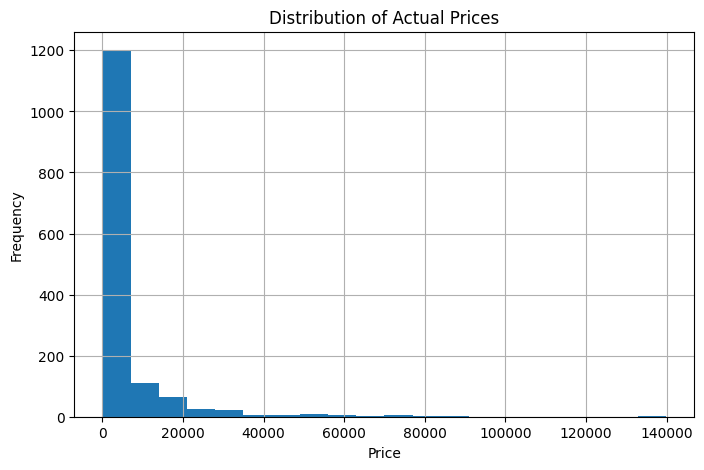

In [ ]:
plt.figure(figsize=(8,5))
data['actual_price'].hist(bins=20)
plt.title('Distribution of Actual Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
data['rating_count'] = data['rating_count'].astype(str).str.replace(',', '',regex=False)
data['rating'] = pd.to_numeric(data['rating'], errors='coerce')
numeric_data=data[
    ['actual_price',
                  'final_price',
                  'discount_percentage',
                  'rating',
                  'rating_count']
]

                     actual_price  final_price  discount_percentage    rating  \
actual_price             1.000000     0.961929            -0.117855  0.122467   
final_price              0.961929     1.000000            -0.242075  0.121146   
discount_percentage     -0.117855    -0.242075             1.000000 -0.155679   
rating                   0.122467     0.121146            -0.155679  1.000000   
rating_count            -0.036215    -0.027402             0.011294  0.102235   

                     rating_count  
actual_price            -0.036215  
final_price             -0.027402  
discount_percentage      0.011294  
rating                   0.102235  
rating_count             1.000000  


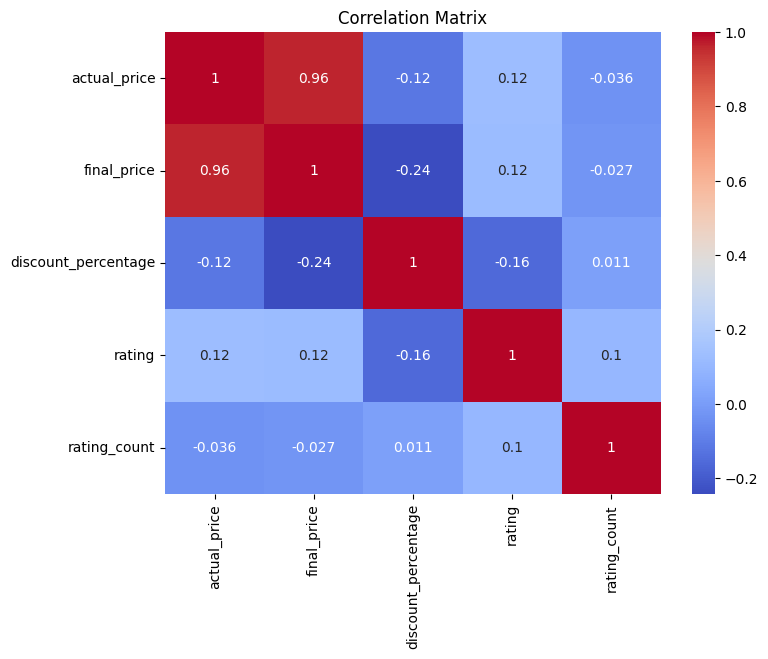

In [ ]:
corr=numeric_data.corr()
print(corr)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
bins=[0,500,1000,5000,float('inf')]
labels=['Low', 'Medium', 'High', 'Premimum']
data['price_range']=pd.cut(data['final_price'],bins=bins,labels=labels)

In [ ]:
def rating_category(r):
  if r>=4.5:
    return 'Excellent'
  elif r>=4.0:
    return 'Good'
  elif r>=3.0:
    return 'Average'
  else:
    return 'Poor'
data['rating_category']=data['rating'].apply(rating_category)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1462 entries, 0 to 1464
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   product_id           1462 non-null   object  
 1   product_name         1462 non-null   object  
 2   category             1462 non-null   object  
 3   discounted_price     1462 non-null   float64 
 4   actual_price         1462 non-null   float64 
 5   discount_percentage  1462 non-null   float64 
 6   rating               1462 non-null   float64 
 7   rating_count         1462 non-null   object  
 8   about_product        1462 non-null   object  
 9   user_id              1462 non-null   object  
 10  user_name            1462 non-null   object  
 11  review_id            1462 non-null   object  
 12  review_title         1462 non-null   object  
 13  review_content       1462 non-null   object  
 14  img_link             1462 non-null   object  
 15  product_link         1462 

In [ ]:
data.to_csv('amazon_cleaned.csv', index=False)

In [ ]:
from google.colab import files
files.download('amazon_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open("amazon_cleaned.csv", "r", encoding="utf-8") as f:
    for i in range(5):
        print(f.readline())

product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,final_price,price_range,rating_category

B07JW9H4J1,"Wayona Nylon Braided USB to Lightning Fast Charging and Data Sync Cable Compatible for iPhone 13, 12,11, X, 8, 7, 6, 5, iPad Air, Pro, Mini (3 FT Pack of 1, Grey)",Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,399.0,1099.0,64.0,4.2,24269,"High Compatibility : Compatible With iPhone 12, 11, X/XsMax/Xr ,iPhone 8/8 Plus,iPhone 7/7 Plus,iPhone 6s/6s Plus,iPhone 6/6 Plus,iPhone 5/5s/5c/se,iPad Pro,iPad Air 1/2,iPad mini 1/2/3,iPod nano7,iPod touch and more apple devices.|Fast Charge&Data Sync : It can charge and sync simultaneously at a rapid speed, Compatible with any charging adaptor, multi-port charging station or power bank.|Durability : Durable nylon braided design with premium aluminum housing and toughene

In [ ]:
data.dtypes


,0
product_id,object
product_name,object
category,object
discounted_price,float64
actual_price,float64
discount_percentage,float64
rating,float64
rating_count,object
about_product,object
user_id,object
